# 04 - Visualização de dados

## 1. Objetivo, escopo e decisões de visualização

Este notebook transforma os dados de mercado, receita, avaliações e cenários em figuras voltadas à leitura gerencial. O objetivo é responder às oito questões do briefing, mantendo preparação e construção de gráficos separadas para reutilização em um aplicativo Streamlit.

**Escopo e convenções:**
- A população observada contém 14 hotéis em Port Alder e registros de 2027-01-04 a 2028-12-31.
- Ocupação é uma proporção entre 0 e 1 nos dados-fonte e será exibida como porcentagem.
- ADR e RevPAR são valores monetários na unidade apresentada pelo arquivo fonte; o projeto não identifica moeda. Por isso, os gráficos usam a unidade `unidade monetária dos dados`, sem converter ou atribuir uma moeda.
- A análise de tiers evita dar peso maior a hotéis com mais quartos ou mais registros: a métrica principal por tier será a média aritmética das médias diárias de hotel.
- Conclusões visuais não são interpretações causais. Sazonalidade, eventos e coincidências temporais são descritos como associação visual ou contexto observado.

**Fontes principais:** `dados/daily_market.jsonl`, `dados/weekly_performance.jsonl`, `dados/reviews.jsonl`, `dados/review_scenarios.jsonl` e `dados/hotels.jsonl`. Os índices e periodos são confirmados a partir dos campos disponíveis nos arquivos e nas etapas anteriores.

## 2. Carregamento e preparação dos dados

As cargas usam caminhos relativos ao diretório `notebooks/`, não dependem de arquivos absolutos e selecionam somente os campos necessários em cada preparação.

In [1]:
from pathlib import Path
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from wordcloud import WordCloud

DATA_DIR = Path('../dados')

# Pontos visuais estáveis por categoria/medida.
TIER_ORDER = ['luxury', 'upscale', 'boutique', 'midscale', 'economy']
TIER_COLORS = {
    'luxury': '#7A5195',
    'upscale': '#3C78D8',
    'boutique': '#D55E00',
    'midscale': '#009E73',
    'economy': '#7F8C8D'
}
SENTIMENT_COLORS = {'positive': '#009E73', 'negative': '#D55E00', 'neutral': '#7F8C8D'}

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titleweight': 'bold'})
sns.set_theme(style='whitegrid', context='notebook')

print('Ambiente de visualização carregado.')

Ambiente de visualização carregado.


In [2]:
df_daily = pd.read_json(DATA_DIR / 'daily_market.jsonl', lines=True)
df_weekly = pd.read_json(DATA_DIR / 'weekly_performance.jsonl', lines=True)
df_reviews = pd.read_json(DATA_DIR / 'reviews.jsonl', lines=True)
df_scenarios = pd.read_json(DATA_DIR / 'review_scenarios.jsonl', lines=True)
df_hotels = pd.read_json(DATA_DIR / 'hotels.jsonl', lines=True)

for frame, column in [(df_daily, 'date'), (df_weekly, 'week_start'), (df_reviews, 'review_date'), (df_reviews, 'stay_date')]:
    frame[column] = pd.to_datetime(frame[column])

print('Período diário:', df_daily['date'].min().date(), 'a', df_daily['date'].max().date())
print('Hotéis:', df_daily['hotel_id'].nunique(), '| Avaliações:', len(df_reviews), '| Cenários:', len(df_scenarios))
print('Tiers disponíveis:', ', '.join(sorted(df_hotels['tier'].dropna().unique())))


Período diário: 2027-01-04 a 2028-12-31
Hotéis: 14 | Avaliações: 12077 | Cenários: 11
Tiers disponíveis: boutique, economy, luxury, midscale, upscale


### Auditoria breve antes das figuras

Os arquivos têm valores diários e semanais para 14 hotéis. A tabela abaixo registra campos relevantes, nulos e unidades/escala inferidos pelos dados. Nulos de `demand_event` serão tratados como períodos sem evento registrado; nulos em medidas numéricas serão excluídos linha a linha nas agregações.

In [3]:
def data_profile(frame, fields, name):
    result = pd.DataFrame({
        'campo': fields,
        'nulos': [int(frame[c].isna().sum()) if c in frame else None for c in fields],
        'tipo': [str(frame[c].dtype) if c in frame else 'ausente' for c in fields]
    })
    result.insert(0, 'arquivo', name)
    return result

profile = pd.concat([
    data_profile(df_daily, ['occupancy','adr','revpar','ari','mpi','rgi','mars_rate','demand_event','date'], 'daily_market.jsonl'),
    data_profile(df_weekly, ['occupancy','adr','revpar','demand_event','week_start','event_nights'], 'weekly_performance.jsonl'),
    data_profile(df_reviews, ['sentiment','text','rating','scenario_id'], 'reviews.jsonl'),
    data_profile(df_scenarios, ['scenario_id','label','share_of_reviews','rating_band'], 'review_scenarios.jsonl'),
    data_profile(df_hotels, ['positioning_index','tier','name'], 'hotels.jsonl')
], ignore_index=True)
profile

,arquivo,campo,nulos,tipo
0,daily_market.jsonl,occupancy,0,float64
1,daily_market.jsonl,adr,0,float64
2,daily_market.jsonl,revpar,0,float64
3,daily_market.jsonl,ari,0,float64
4,daily_market.jsonl,mpi,0,float64
5,daily_market.jsonl,rgi,0,float64
6,daily_market.jsonl,mars_rate,0,float64
7,daily_market.jsonl,demand_event,0,str
8,daily_market.jsonl,date,0,datetime64[us]
9,weekly_performance.jsonl,occupancy,0,float64


## 3. Configuração visual comum e funções reutilizáveis

A preparação recebe os nomes dos campos diretamente; as funções abaixo recebem DataFrames e parâmetros e retornam objetos de figura. Assim, podem ser chamadas por uma camada Streamlit sem reproduzir cálculos dentro dos gráficos.

In [4]:
def summarize_tiers_equal_hotels(df_daily):
    required = ['hotel_id','tier','occupancy','adr','revpar']
    valid = df_daily[required].dropna(subset=['occupancy','adr','revpar'])
    hotel_means = (valid
                   .groupby(['tier','hotel_id'], as_index=False)
                   .agg(occupancy=('occupancy','mean'),
                        adr=('adr','mean'),
                        revpar=('revpar','mean')))
    tier_means = (hotel_means
                  .groupby('tier', as_index=False)
                  .agg(occupancy=('occupancy','mean'),
                       adr=('adr','mean'),
                       revpar=('revpar','mean'),
                       hoteis=('hotel_id','nunique')))
    return tier_means.set_index('tier').reindex(TIER_ORDER).dropna(how='all').reset_index()


def make_tier_small_multiples(summary):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    measures = [
        ('occupancy', 'Ocupação média', 'Ocupação (%)', 100),
        ('adr', 'ADR médio', 'ADR (unidade monetária dos dados)', 1),
        ('revpar', 'RevPAR médio', 'RevPAR (unidade monetária dos dados)', 1)
    ]
    for ax, (column, title, ylabel, scale) in zip(axes, measures):
        values = summary[column] * scale
        bars = ax.bar(summary['tier'], values,
                      color=[TIER_COLORS[t] for t in summary['tier']], edgecolor='white')
        ax.set_title(title)
        ax.set_xlabel('Tier')
        ax.set_ylabel(ylabel)
        ax.tick_params(axis='x', rotation=35)
        ax.bar_label(bars, labels=[f'{v:.1f}' for v in values], padding=3, fontsize=9)
        ax.spines[['top','right']].set_visible(False)
    fig.suptitle('Boutique lidera ocupação; tiers superiores concentram ADR e RevPAR mais altos', y=1.02, fontsize=13)
    fig.tight_layout()
    return fig


def make_temporal_figure(df_weekly):
    weekly = df_weekly.copy()
    weekly['week_start'] = pd.to_datetime(weekly['week_start'])
    grouped = (weekly.groupby('week_start', as_index=False)
               .agg(occupancy=('occupancy','mean'),
                    adr=('adr','mean'))
               .sort_values('week_start'))

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=grouped['week_start'], y=grouped['occupancy']*100,
                             mode='lines', name='Ocupação', line=dict(color='#3C78D8', width=2)))
    fig.update_layout(title='A ocupação semanal apresenta oscilações sazonais recorrentes ao longo dos dois anos',
                      xaxis_title='Semana', yaxis_title='Ocupação média (%)', template='plotly_white',
                      height=500, legend=dict(orientation='h'))

    events = (weekly.dropna(subset=['demand_event'])
              .loc[lambda x: x['demand_event'].astype(str).str.strip() != '']
              .groupby(['week_start','demand_event'], as_index=False).size())
    event_colors = px.colors.qualitative.Dark24
    event_names = sorted(events['demand_event'].unique())
    for i, event in enumerate(event_names):
        subset = events[events['demand_event'] == event]
        joined = subset.merge(grouped[['week_start','occupancy']], on='week_start', how='left')
        fig.add_trace(go.Scatter(x=joined['week_start'], y=joined['occupancy']*100,
                                 mode='markers', name=event,
                                 marker=dict(symbol='diamond', size=8, color=event_colors[i % len(event_colors)]),
                                 hovertemplate='%{x|%Y-%m-%d}<br>' + event + '<br>Ocupação: %{y:.1f}%<extra></extra>'))

    fig.add_trace(go.Scatter(x=grouped['week_start'], y=grouped['adr'],
                             mode='lines', name='ADR', line=dict(color='#D55E00', width=2), yaxis='y2'))
    fig.update_layout(yaxis2=dict(title='ADR (unidade monetária dos dados)', overlaying='y', side='right', showgrid=False))
    return fig


def make_competitive_map(df_daily, df_hotels):
    hotel_period = (df_daily.dropna(subset=['ari','mpi'])
                    .groupby(['hotel_id','hotel_name','tier'], as_index=False)
                    .agg(ari=('ari','mean'), mpi=('mpi','mean'), obs=('date','count')))
    hotel_period = hotel_period.merge(df_hotels[['hotel_id','name']], on='hotel_id', how='left')
    hotel_period['quadrante'] = np.select(
        [
            (hotel_period['ari'] >= 100) & (hotel_period['mpi'] >= 100),
            (hotel_period['ari'] >= 100) & (hotel_period['mpi'] < 100),
            (hotel_period['ari'] < 100) & (hotel_period['mpi'] >= 100),
        ],
        [
            'Preço acima | ocupação acima',
            'Preço acima | ocupação abaixo',
            'Preço abaixo | ocupação acima',
        ],
        default='Preço abaixo | ocupação abaixo'
    )

    fig = px.scatter(hotel_period, x='ari', y='mpi', color='tier', symbol='tier',
                     category_orders={'tier': TIER_ORDER},
                     color_discrete_map=TIER_COLORS,
                     hover_name='name',
                     hover_data={'hotel_id': True, 'ari': ':.1f', 'mpi': ':.1f', 'obs': True,
                                 'tier': True, 'name': False},
                     labels={'ari':'Índice ADR contra concorrentes (ARI)',
                             'mpi':'Índice de ocupação contra concorrentes (MPI)',
                             'tier':'Tier'},
                     title='Alguns hotéis cobram acima da paridade e ainda têm ocupação abaixo do conjunto competitivo')
    fig.add_vline(x=100, line_dash='dash', line_color='#555555')
    fig.add_hline(y=100, line_dash='dash', line_color='#555555')
    fig.update_traces(marker=dict(size=11, line=dict(width=1, color='white')))
    fig.update_layout(template='plotly_white', height=620,
                      xaxis=dict(range=[hotel_period['ari'].min()-3, hotel_period['ari'].max()+3], zeroline=False),
                      yaxis=dict(range=[hotel_period['mpi'].min()-3, hotel_period['mpi'].max()+3], zeroline=False))
    fig.add_annotation(x=hotel_period['ari'].max()+1, y=hotel_period['mpi'].max()+1,
                       text='Preço acima | ocupação acima', showarrow=False, xanchor='right')
    fig.add_annotation(x=hotel_period['ari'].min()-1, y=hotel_period['mpi'].max()+1,
                       text='Preço abaixo | ocupação acima', showarrow=False, xanchor='left')
    fig.add_annotation(x=hotel_period['ari'].max()+1, y=hotel_period['mpi'].min()-1,
                       text='Preço acima | ocupação abaixo', showarrow=False, xanchor='right')
    fig.add_annotation(x=hotel_period['ari'].min()-1, y=hotel_period['mpi'].min()-1,
                       text='Preço abaixo | ocupação abaixo', showarrow=False, xanchor='left')
    for _, row in hotel_period.iterrows():
        fig.add_annotation(x=row['ari'], y=row['mpi'], text=row['hotel_id'],
                           showarrow=False, yshift=12, font=dict(size=9))
    return fig, hotel_period


def make_mars_boxplot(df_daily):
    valid = df_daily[['hotel_id','hotel_name','tier','adr','mars_rate']].copy()
    valid = valid[(valid['mars_rate'].notna()) & (valid['mars_rate'] > 0) &
                  (valid['adr'].notna())].copy()
    valid['desvio_mars_pct'] = (valid['adr'] - valid['mars_rate']) / valid['mars_rate'] * 100

    fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(data=valid, x='tier', y='desvio_mars_pct', order=TIER_ORDER,
                palette=TIER_COLORS, width=.65, ax=ax, fliersize=2, linewidth=1)
    sns.stripplot(data=valid, x='tier', y='desvio_mars_pct', order=TIER_ORDER,
                  color='#34495E', alpha=.12, size=1.5, jitter=.22, ax=ax)
    ax.axhline(0, color='#111111', linewidth=1.2, linestyle='--')
    ax.set_title('A dispersão diária do desvio em relação à MARS é pequena em todos os tiers')
    ax.set_xlabel('Tier')
    ax.set_ylabel('Desvio de ADR versus MARS (%)')
    ax.spines[['top','right']].set_visible(False)
    fig.tight_layout()
    return fig, valid


def make_scenario_bar(df_reviews, df_scenarios):
    counts = (df_reviews.groupby('scenario_id', as_index=False)
              .agg(count=('review_id','count')))
    counts = df_scenarios.merge(counts, on='scenario_id', how='left').fillna({'count':0})
    counts['share_observed_pct'] = counts['count'] / counts['count'].sum() * 100
    counts = counts.sort_values(['count','label'], ascending=[True, True])

    fig, ax = plt.subplots(figsize=(11, 6))
    bars = ax.barh(counts['label'], counts['count'], color='#3C78D8')
    ax.set_title('Delight e room condition concentram a maior parte das avaliações observadas')
    ax.set_xlabel('Quantidade observada de avaliações')
    ax.set_ylabel('Cenário')
    ax.bar_label(bars, labels=[f'{int(v)} | {p:.1f}%'.replace('.', ',')
                               for v, p in zip(counts['count'], counts['share_observed_pct'])],
                 padding=3, fontsize=9)
    ax.spines[['top','right']].set_visible(False)
    fig.tight_layout()
    return fig, counts


def make_sankey(df_reviews, df_scenarios):
    joined = df_reviews.merge(df_scenarios[['scenario_id','label']], on='scenario_id', how='left')
    joined = joined.copy()
    joined['rating_band'] = pd.cut(joined['rating'], bins=[0,2,3,5], labels=['1-2','3','4-5'])
    joined = joined.dropna(subset=['label','rating_band'])
    flow = (joined.groupby(['label','rating_band'], observed=True)
            .agg(count=('review_id','nunique')).reset_index())

    scenario_names = sorted(flow['label'].unique())
    band_names = ['Nota 1-2','Nota 3','Nota 4-5']
    node_names = scenario_names + band_names
    node_index = {name:i for i,name in enumerate(node_names)}

    source = [node_index[label] for label in flow['label']]
    target = [node_index['Nota ' + str(band)] for band in flow['rating_band']]
    values = flow['count'].tolist()

    fig = go.Figure(go.Sankey(
        arrangement='snap',
        node=dict(pad=16, thickness=15,
                  label=node_names,
                  color=['#7F8C8D']*len(scenario_names) + ['#D55E00','#E69F00','#009E73']),
        link=dict(source=source, target=target, value=values,
                  color='rgba(120,120,120,0.22)')
    ))
    fig.update_layout(title='Cenários positivos predominam em notas 4-5; cenários negativos predominam em notas 1-3',
                      font=dict(size=11), height=650, template='plotly_white')
    return fig, flow


def clean_review_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\sÀ-ÿ]', ' ', text)
    tokens = text.split()

    portuguese = set('''a à ao aos as com contra da das de do dos e ela elas ele eles em entre era eram esse essa esses essas este esta estes estas eu lhe lhes mas me meu meus minha minhas na nas no nos o os ou para pela pelas pelo pelos por que quem se sem sua suas seu seus sua sou somos são só também te teu teus tua tuas você vocês já mais muito muita muitos muitas não numa num no não lhe sua seu dele dela deles delas de da do dos das aos às uma um uns umas'''.split())
    english = set('''a about above after again against all am an and any are as at be because been before being below between both but by can did do does doing down each few for from further had has have having he her here hers herself him himself his how i if in into is it its itself just me more most my myself no nor not of off on once only or other our ours ourselves out over own same she should so some such than that the their theirs them themselves then there these they this those through to too under until up very was we were what when where which while who whom why will with you your yours yourself yourselves'''.split())
    domain_common = {'hotel','stay','night','nights','room','rooms','us','guest','guests','one','get','got','would','really','good','great','booking','booked'}
    stopwords = portuguese | english | domain_common
    return ' '.join(t for t in tokens if len(t) >= 3 and t not in stopwords)


def make_wordcloud(text, title, sentiment):
    cmap = 'Greens' if sentiment == 'positive' else 'Reds'
    wc = WordCloud(width=900, height=500, background_color='white',
                   colormap=cmap, max_words=30, relative_scaling=.5,
                   collocations=False).generate(text)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title)
    ax.axis('off')
    fig.tight_layout()
    return fig


## 4. Visualizações e respostas às perguntas

### 4.1 Comparação dos tiers

**Tipo escolhido:** pequenos múltiplos de barras com a mesma ordenação de tiers. Barras facilitam comparar categorias dentro de cada medida e múltiplos evitam misturar ocupação, ADR e RevPAR em uma única escala.

**Fonte, unidade e agregação:** `daily_market.jsonl`; ocupação em proporção convertida para `%`, ADR e RevPAR na unidade monetária dos dados, uma observação por hotel-dia. Primeiro calcula-se a média de cada hotel no período; em seguida, a média aritmética dos hotéis dentro de cada tier dá o mesmo peso a cada hotel. Nulos de ocupação/ADR/RevPAR são excluídos do cálculo. RevPAR é receita de quartos por quarto disponível, não receita total.


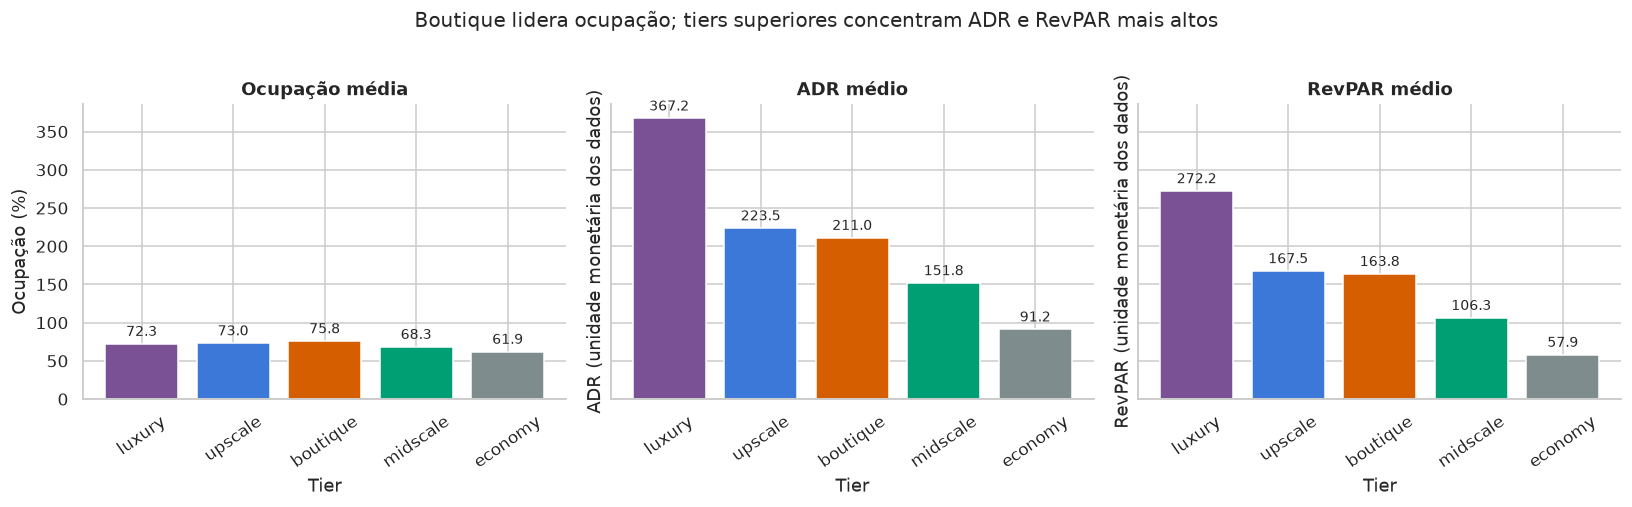

,tier,occupancy,adr,revpar,hoteis
0,luxury,0.7233,367.23,272.16,2
1,upscale,0.7305,223.51,167.50,4
2,boutique,0.7580,211.05,163.82,3
3,midscale,0.6833,151.76,106.26,3
4,economy,0.6194,91.22,57.94,2


In [5]:
tier_summary = summarize_tiers_equal_hotels(df_daily)
fig_tiers = make_tier_small_multiples(tier_summary)
plt.show()
tier_summary.round({'occupancy':4,'adr':2,'revpar':2})

**O que concluir:** a ocupação máxima aparece em boutique, enquanto os tiers superiores apresentam os maiores ADR e RevPAR médios. Essas diferenças são médias entre hotéis no período observado, não uma classificação de desempenho individual.

### 4.2 Evolução temporal e eventos de demanda

**Tipo escolhido:** gráfico interativo de linhas com ocupação e ADR em eixos separados. Marcadores em diamante identificam as semanas com eventos registrados, codificados por cor e legenda.

**Fonte, unidade e agregação:** `weekly_performance.jsonl`, granularidade semanal por hotel. No gráfico combinado, ocupação e ADR são médias simples das observações semanais dos hotéis. Essa escolha dá peso visual a hotéis por registro, mas o arquivo possui 104 semanas para cada hotel. Períodos sem observação não aparecem como linha contínua artificial; no agregado completo não foram encontrados períodos faltantes. Eventos vazios são tratados como ausência de evento. Sazonalidade ou agregação pode ocultar diferenças de hotéis individuais.


In [6]:
fig_temporal = make_temporal_figure(df_weekly)
fig_temporal.show()

**O que concluir:** ocupação e ADR oscilam ao longo do período e coincidem visualmente com alguns eventos marcados. A coincidência no tempo não estabelece efeito dos eventos sobre demanda ou preço.

### 4.3 Mapa de posicionamento competitivo

**Tipo escolhido:** dispersão Plotly com quadrantes e tooltips. A dispersão permite um ponto por hotel e permite localizar simultaneamente preço relativo e ocupação relativa.

**Fonte, unidade e agregação:** fonte `dados/daily_market.jsonl` e metadados de `dados/hotels.jsonl`, granularidade diária por hotel. Os índices são adimensionais (base 100), calculados pelo período completo como médias diárias simples por hotel. Linhas com ARI ou MPI nulo são excluídas antes da agregação.


**Definição dos eixos:** o índice horizontal é `ari` (ADR contra o conjunto competitivo) e o vertical é `mpi` (índice de ocupação contra o conjunto competitivo). Para os dados fornecidos, a relação observada é `ARI = ADR / comp_set_adr × 100` e `MPI = ocupação / comp_set_occupancy × 100`. A paridade é 100 em ambos: acima de 100 significa resultado acima do conjunto competitivo. Este uso é diferente do índice cadastral `positioning_index`: o índice cadastral não entra no mapa, pois representa posicionamento cadastral, não preço realizado.


In [7]:
fig_comp, hotel_period = make_competitive_map(df_daily, df_hotels)
fig_comp.show()
(hotel_period[['hotel_id','name','tier','ari','mpi','obs','quadrante']]
 .sort_values(['mpi','ari'], ascending=[False,False])
 .round({'ari':1,'mpi':1}))

print('\nHotéis por quadrante:')
for quadrante, rows in hotel_period.groupby('quadrante', sort=False):
    names = ', '.join(rows.sort_values('ari', ascending=False)['name'])
    print(f'- {quadrante}: {names}')


Hotéis por quadrante:
- Preço acima | ocupação acima: Harborlight Suites, Northgate Inn, Marisol Bay Resort, Kestrel Park Hotel, Alder & Quay Hotel
- Preço acima | ocupação abaixo: The Lantern House
- Preço abaixo | ocupação abaixo: Seabright Grand, Cedar & Salt Hotel, Willowmere Lodge, The Copper Meridian, Ridgeline Motor Inn, The Foxglove
- Preço abaixo | ocupação acima: Paloma Court Hotel, The Wren Rooms


**O que concluir:** hotéis acima de 100 em ambos os eixos têm preço e ocupação acima da paridade competitiva; os demais quadrantes precisam ser interpretados separadamente. Pontos próximos à linha 100 têm distância limitada da paridade e não devem ser chamados extremos.

### 4.4 Desvio entre preço praticado e diária MARS

**Tipo escolhido:** boxplot por tier com pontos de sobreposição. A forma revela mediana, quartis e extremos sem ocultar a dispersão entre dias.

**Cálculo:** `desvio (%) = (ADR - mars_rate) / mars_rate * 100`. São confirmados: ADR e `mars_rate` usam a unidade monetária dos dados e `mars_rate > 0` foi exigido. O período é 2027-01-04 a 2028-12-31, granularidade diária. Linhas com ADR ou MARS nula e MARS não positiva são excluídas. Um resultado positivo significa ADR acima da MARS; negativo, abaixo; zero, paridade. Isso não mede adequação da tarifa.


/tmp/ipykernel_15610/4158045134.py:130: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid, x='tier', y='desvio_mars_pct', order=TIER_ORDER,


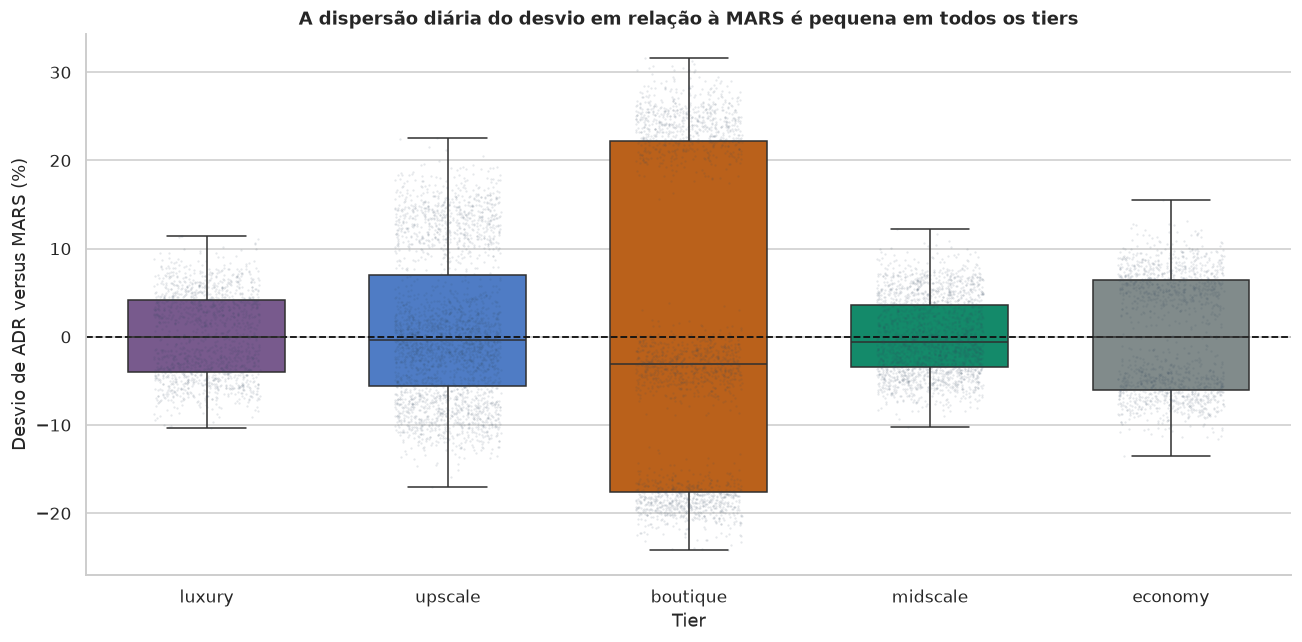

Observações válidas: 10192


,count,median,mean,std,min,max
tier,,,,,,
luxury,1456,-0.00,0.11,4.74,-10.29,11.47
upscale,2912,-0.40,0.93,8.34,-17.00,22.58
boutique,2184,-3.13,0.72,17.72,-24.21,31.57
midscale,2184,-0.56,0.03,4.25,-10.25,12.18
economy,1456,0.00,0.22,6.60,-13.46,15.55


In [8]:
fig_mars, mars = make_mars_boxplot(df_daily)
plt.show()
summary_mars = (mars.groupby('tier')['desvio_mars_pct']
                .agg(['count','median','mean','std','min','max'])
                .reindex(TIER_ORDER)
                .round(2))
print('Observações válidas:', len(mars))
summary_mars

**O que concluir:** a mediana por tier indica a direção típica do desvio, enquanto a caixa e os pontos mostram quanto as tarifas variam dentro e entre os grupos. Valores extremos são observações reais dos dados e não foram tratados como erros sem confirmação.

### 4.5 Distribuição dos cenários das avaliações

**Tipo escolhido:** barras horizontais ordenadas. Elas tornam 11 categorias comparáveis sem sugerir que fatias representam apenas partes menos precisas de um total.

**Fonte e agregação:** junção observada de `reviews.jsonl` com `review_scenarios.jsonl` pelo `scenario_id`; contagem distinta de `review_id`. A participação exibida é calculada a partir das avaliações observadas. O campo `share_of_reviews` do catálogo é uma participação planejada ou declarada e não é usado como frequência calculada.


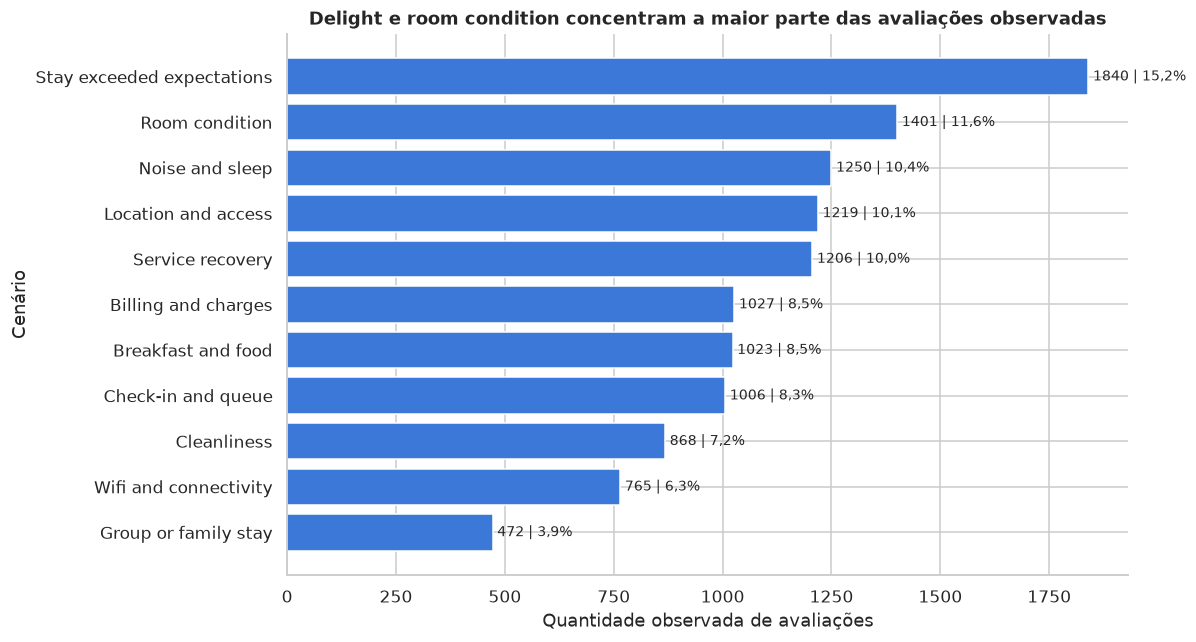

,scenario_id,label,count,share_observed_pct,share_of_reviews
0,delight,Stay exceeded expectations,1840,15.24,0.15
4,room_condition,Room condition,1401,11.60,0.11
5,noise,Noise and sleep,1250,10.35,0.10
1,location,Location and access,1219,10.09,0.10
3,service_recovery,Service recovery,1206,9.99,0.10
7,billing,Billing and charges,1027,8.50,0.08
2,breakfast,Breakfast and food,1023,8.47,0.09
6,checkin_wait,Check-in and queue,1006,8.33,0.09
9,cleanliness,Cleanliness,868,7.19,0.07
8,wifi,Wifi and connectivity,765,6.33,0.07


In [9]:
fig_scenarios, scenario_counts = make_scenario_bar(df_reviews, df_scenarios)
plt.show()
scenario_counts[['scenario_id','label','count','share_observed_pct','share_of_reviews']].sort_values('count', ascending=False).round({'share_observed_pct':2,'share_of_reviews':4})

**O que concluir:** os cenários com maior barra concentram mais avaliações observadas. A participação calculada difere conceitualmente da participação planejada `share_of_reviews` do catálogo.

### 4.6 Fluxo das avaliações — cenário para faixa de nota

**Tipo escolhido:** Sankey. Os nós representam os cenários e três faixas de nota; a largura do fluxo usa contagens observadas de avaliações distintas.

**Tratamento:** foi feita uma junção direta por `scenario_id`, sem expansão de registros. Avaliações sem cenário ou sem nota válida foram excluídas dessa visualização; a quantidade excluída é registrada abaixo. A banda foi definida como 1-2, 3 e 4-5.


In [10]:
fig_sankey, sankey_flow = make_sankey(df_reviews, df_scenarios)
fig_sankey.show()
joined_check = df_reviews.merge(df_scenarios[['scenario_id','label']], on='scenario_id', how='left')
print('Avaliações válidas no Sankey:', sankey_flow['count'].sum())
print('Avaliações sem cenário, nota ou rótulo:', len(joined_check) - sankey_flow['count'].sum())
sankey_flow.sort_values('count', ascending=False).head(10)

Avaliações válidas no Sankey: 12077
Avaliações sem cenário, nota ou rótulo: 0


,label,rating_band,count
18,Stay exceeded expectations,4-5,1840
11,Location and access,4-5,1219
17,Service recovery,4-5,1069
0,Billing and charges,1-2,909
15,Room condition,3,753
7,Cleanliness,1-2,735
3,Breakfast and food,4-5,661
14,Room condition,1-2,648
13,Noise and sleep,3,637
12,Noise and sleep,1-2,613


**O que concluir:** os maiores fluxos mostram quais cenários concentram volume nas respectivas faixas de nota. O diagrama descreve associação por categoria e não uma sequência temporal nem causalidade.

### 4.7 Nuvens de palavras — avaliações positivas e negativas

**Identificação dos grupos:** o campo existente `sentiment` define positivo e negativo; não é aplicada classificação improvisada no texto. São incluídos todos os registros com `sentiment == "positive"` ou `"negative"`, independentemente de rating.

**Pré-processamento:** texto convertido para minúsculas, pontuação removida, tokens com menos de três caracteres excluídos e stopwords em português e inglês removidas. Stopwords adicionais do domínio são apenas palavras genéricas pouco informativas (`hotel`, `room`, `stay`, `night`, `booking`, `guest`, entre outras). Ambas as nuvens usam `width=900`, `height=500`, `max_words=30`, `relative_scaling=.5` e `collocations=False`. Avaliações neutras são omitidas por não pertencerem aos dois grupos definidos. O tamanho representa frequência, não importância ou representatividade causal.

Avaliações positivas incluídas: 4,415
Avaliações negativas incluídas: 5,379


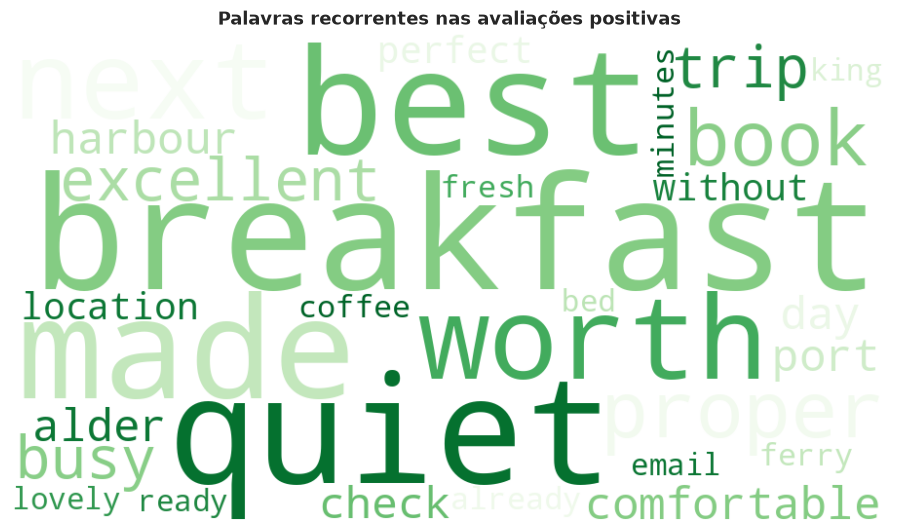

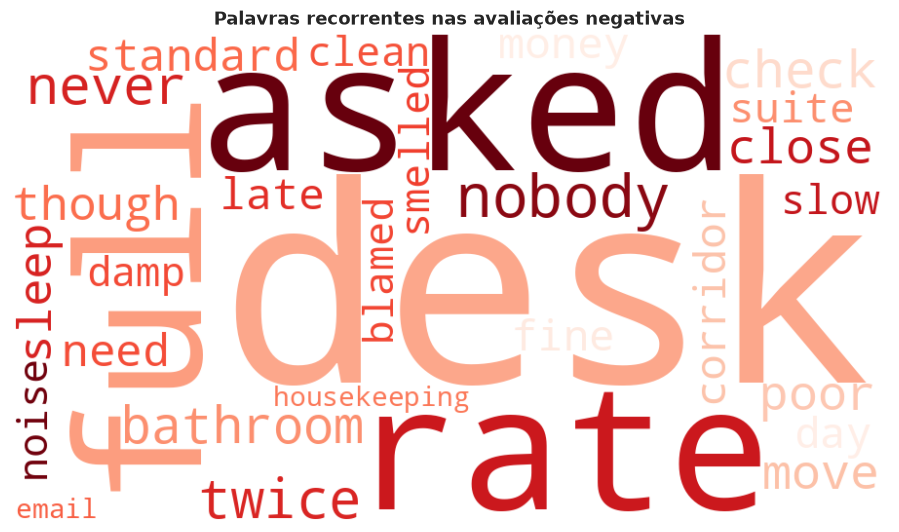

In [11]:
positive_text = ' '.join(
    clean_review_text(t) for t in df_reviews.loc[df_reviews['sentiment'].eq('positive'), 'text'].dropna()
)
negative_text = ' '.join(
    clean_review_text(t) for t in df_reviews.loc[df_reviews['sentiment'].eq('negative'), 'text'].dropna()
)

n_positive = int(df_reviews['sentiment'].eq('positive').sum())
n_negative = int(df_reviews['sentiment'].eq('negative').sum())
print(f'Avaliações positivas incluídas: {n_positive:,}')
print(f'Avaliações negativas incluídas: {n_negative:,}')

fig_positive = make_wordcloud(positive_text, 'Palavras recorrentes nas avaliações positivas', 'positive')
plt.show()

fig_negative = make_wordcloud(negative_text, 'Palavras recorrentes nas avaliações negativas', 'negative')
plt.show()

**O que concluir:** a nuvem positiva destaca termos recorrentes nas avaliações positivas, enquanto a negativa destaca recorrência nas avaliações negativas. Frequência visual não indica importância isolada, causalidade ou representatividade além das avaliações incluídas.

## 5. Síntese dos achados e limitações

**Observações principais:**
- Os tiers diferem em ocupação, ADR e RevPAR; essas medidas não compartilham uma única escala e devem ser lidas em seus próprios painéis.
- A evolução semanal mostra mudanças em ocupação e ADR ao longo dos dois anos. Os eventos registrados aparecem como marcadores, mas não permitem atribuir causa às variações.
- O mapa competitivo usa ARI e MPI em paridade 100. Ele permite distinguir hotéis com preço e ocupação relativos acima ou abaixo dos concorrentes, com incerteza maior perto da paridade.
- O desvio em relação à MARS varia por dia e tier e não prova que uma tarifa seja adequada ou inadequada.
- Os cenários das avaliações são comparados pela frequência observada; `share_of_reviews` não é confundido com essa frequência.
- O Sankey concentra volumes de cenários em faixas de nota e o texto positivo/negativo revela palavras recorrentes, não relações causais.

**Limitações:**
- As médias agregadas podem ocultar dispersão e a distribuição temporal dos hotéis individuais.
- O período contém dados fornecidos para 14 hotéis em um único mercado; os resultados não representam uma amostra probabilística de um mercado maior.
- O projeto não fornece moeda nominal para ADR, RevPAR e MARS; por isso os valores monetários não recebem conversão ou símbolo.
- Os índices são usados conforme os campos disponíveis; o significado detalhado ou fórmula de ARI/MPI não está documentado fora dos dados.
- A nuvem depende da qualidade dos textos e da limpeza em palavras genéricas; palavras frequentes não representam todos os hóspedes nem causalidade.
- O Sankey usa contagens observadas e não define uma relação sequencial entre cenário e nota.

## 6. Referências às fontes e às definições utilizadas

- `dados/daily_market.jsonl`: mercado diário, ADR, ocupação, RevPAR, ARI, MPI, MARS e eventos de demanda.
- `dados/weekly_performance.jsonl`: desempenho semanal agregado por hotel e eventos semanais.
- `dados/reviews.jsonl`: avaliações, sentimento, nota, cenário e texto.
- `dados/review_scenarios.jsonl`: rótulo, participação declarada, faixa de nota e informações de ação dos cenários.
- `dados/hotels.jsonl`: nome, tier e metadados dos hotéis.
- Notebook da Etapa 2: princípios de agregação, ocupação típica e cautela contra causalidade.
- Notebook da Etapa 3: estrutura relacional, dimensões e ligações entre avaliações e cenários.

As decisões adotadas neste notebook permanecem coerentes com esses materiais; lacunas de definição são registradas como limites ou hipóteses explícitas.